In [1]:
no_of_threads = "12"

import os
os.environ["VECLIB_MAXIMUM_THREADS"] = no_of_threads
os.environ["OMP_NUM_THREADS"] = no_of_threads


In [2]:
%pip install matplotlib



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
B=1 #Batchsize

In [4]:


import torch
from torch import linalg as LA
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import time
import statistics
from typing import Tuple
from typing_extensions import Annotated
import transformers
import psutil

from transformers import AutoModelForCausalLM, AutoTokenizer
import json
import platform
import subprocess
import time
import re

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
REVISION = "989aa7980e4cf806f80c7fef2b1adb7bc71aa306"   

#model_hf = AutoModelForCausalLM.from_pretrained(
#    MODEL_ID, revision=REVISION, dtype=torch.float32, device_map="cpu"
#)

model_hf = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=torch.float32
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)

Loading weights: 100%|██████████| 338/338 [00:01<00:00, 197.02it/s]


In [6]:


def extract_letter(text):
   
    for pat in (r"answer is\s*:?\s*\(?([A-E1-5])\b",  
                r"^\s*\(?([A-E1-5])[\).:]",           
                r"\b([A-E1-5])[\).]"):                
        m = re.search(pat, text, re.I | re.M)
        if m:
            return m.group(1).upper()
    return None

tokenizer.padding_side = "left"
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def time_counter(no_of_threads: int, model, tokenizer, prompts: list, results: list,
                 answer_keys: list = None, max_new_tokens: int = 128,
                 batch_size: int = B, repeats: int = 3):

    torch.set_num_threads(int(no_of_threads))
    print("threads:", torch.get_num_threads())
    time.sleep(2)
    proc = psutil.Process(os.getpid())

    for start in range(0, len(prompts), batch_size):
        ids = list(range(start, min(start + batch_size, len(prompts))))
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": prompts[i]}],
                                               tokenize=False, add_generation_prompt=True)
                 for i in ids]
        
        
        model_inputs = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        print(model_inputs["input_ids"][:, :5])
        print(tokenizer.pad_token_id)
        input_len = model_inputs["input_ids"].shape[1]

        with torch.inference_mode():
            
            model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)

            n_lst = []
            for i in range(repeats):
                start_time = time.perf_counter()
                out_put_ids = model.generate(**model_inputs, max_new_tokens=max_new_tokens, do_sample=False,
                               pad_token_id=tokenizer.pad_token_id)
                end_time = time.perf_counter()
                n_lst.append(end_time - start_time)

        mean = statistics.mean(n_lst)
        stndev = statistics.stdev(n_lst) if len(n_lst) > 1 else 0.0
        mem_gb = proc.memory_info().rss / 1e9
        gen = out_put_ids[:, input_len:]
        n_new = (gen != tokenizer.pad_token_id).sum(dim=1).tolist()
        for row, pid in enumerate(ids):
            answer = tokenizer.decode(gen[row], skip_special_tokens=True)
            letter = extract_letter(answer)
            n_dict = {
                'thread': torch.get_num_threads(),
                'batch_size': batch_size,
                'batch_start': start,
                'prompt_id': pid,
                'batch_mean': mean,
                'batch_stdev': stndev,
                'input_tokens': input_len,
                'new_tokens': n_new[row],
                'mem_gb': mem_gb,
                'answer': answer,
                'pred': letter,
            }
            if answer_keys is not None:
                n_dict['key'] = answer_keys[pid]
                n_dict['correct'] = (letter == answer_keys[pid])
            results.append(n_dict)


        

In [7]:
results = []

# 64 questions, 16 each of A/B/C/D. Built by select_prompts.py
with open("prompts_arc64_balanced.json") as f:
    data = json.load(f)
prompts, answer_keys = data["prompts"], data["answer_keys"]
print(len(prompts), len(answer_keys))   # 64 64

64 64


In [8]:
results = []

for t in range(1,13):
    time_counter(t, model_hf, tokenizer, prompts[:1], results, answer_keys=answer_keys, repeats=1)
    print("done", t, "threads,", len(results), "rows")


threads: 1
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 1 threads, 1 rows
threads: 2
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 2 threads, 2 rows
threads: 3
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 3 threads, 3 rows
threads: 4
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 4 threads, 4 rows
threads: 5
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 5 threads, 5 rows
threads: 6
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 6 threads, 6 rows
threads: 7
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 7 threads, 7 rows
threads: 8
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 8 threads, 8 rows
threads: 9
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 9 threads, 9 rows
threads: 10
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 10 threads, 10 rows
threads: 11
tensor([[151644,   8948,    198,   2610,    525]])
151643
done 11

In [9]:
results

[{'thread': 1,
  'batch_size': 1,
  'batch_start': 0,
  'prompt_id': 0,
  'batch_mean': 6.170236250036396,
  'batch_stdev': 0.0,
  'input_tokens': 109,
  'new_tokens': 88,
  'mem_gb': 6.85432832,
  'answer': 'B. Protein is made up of amino acids.\n\nExplanation: Proteins are composed of long chains of amino acids linked together through peptide bonds. Each amino acid has a specific sequence that determines its function within the protein structure. The process of forming proteins from amino acids is called protein synthesis or translation in molecular biology. This involves the ribosome reading the genetic code encoded in mRNA to assemble the correct sequence of amino acids into a functional protein.',
  'pred': 'B',
  'key': 'B',
  'correct': True},
 {'thread': 2,
  'batch_size': 1,
  'batch_start': 0,
  'prompt_id': 0,
  'batch_mean': 6.179874500026926,
  'batch_stdev': 0.0,
  'input_tokens': 109,
  'new_tokens': 88,
  'mem_gb': 6.857474048,
  'answer': 'B. Protein is made up of amin

In [10]:
print(torch.__config__.show())

PyTorch built with:
  - GCC 4.2
  - C++ Version: 202002
  - clang 21.0.0
  - OpenMP 202011
  - LAPACK is enabled (usually provided by MKL)
  - NNPACK is enabled
  - CPU capability usage: DEFAULT
  - Build settings: BLAS_INFO=accelerate, BUILD_TYPE=Release, COMMIT_SHA=5c4886908584029761b579af026dcfb627c84070, CUDA_FLAGS= -DLIBCUDACXX_ENABLE_SIMPLIFIED_COMPLEX_OPERATIONS -Xfatbin -compress-all  -Wno-deprecated-gpu-targets --expt-extended-lambda -DCUB_WRAPPED_NAMESPACE=at_cuda_detail -DDISABLE_CUSPARSE_DEPRECATED -DCUDA_HAS_FP16=1 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -DC10_NODEPRECATED, CXX_COMPILER=/usr/bin/c++, CXX_FLAGS= -fvisibility-inlines-hidden -DUSE_PTHREADPOOL -DNDEBUG -DUSE_KINETO -DUSE_PYTORCH_QNNPACK -DAT_BUILD_ARM_VEC256_WITH_SLEEF -DUSE_PYTORCH_METAL_EXPORT -DSYMBOLICATE_MOBILE_DEBUG_HANDLE -DUSE_COREML_DELEGATE -O2 -fPIC -DC10_NODEPRECATED -Wall -Wextra -Werror=return-type -Werror=non-vi

In [11]:
df = pd.DataFrame(results)
per_batch = df.drop_duplicates(["thread", "batch_start"])        
total = per_batch.groupby("thread")["batch_mean"].sum()          
t1 = total.loc[1]

n_res = []
for n, t in total.items():
    speedup = t1 / t
    n_res.append({
        "threads": n,
        "mean": t,
        "speedup": speedup,
        "efficiency": speedup / n * 100,
        "serial_fraction": ((n / speedup - 1) / (n - 1)) * 100 if n > 1 else None,
    })

In [12]:
n_res

[{'threads': 1,
  'mean': 6.170236250036396,
  'speedup': np.float64(1.0),
  'efficiency': np.float64(100.0),
  'serial_fraction': None},
 {'threads': 2,
  'mean': 6.179874500026926,
  'speedup': np.float64(0.9984403809510228),
  'efficiency': np.float64(49.92201904755114),
  'serial_fraction': np.float64(100.31241105202326)},
 {'threads': 3,
  'mean': 6.172051417059265,
  'speedup': np.float64(0.9997059053951087),
  'efficiency': np.float64(33.32353017983696),
  'serial_fraction': np.float64(100.04412716829583)},
 {'threads': 4,
  'mean': 6.187191250035539,
  'speedup': np.float64(0.9972596612398161),
  'efficiency': np.float64(24.9314915309954),
  'serial_fraction': np.float64(100.36638251356082)},
 {'threads': 5,
  'mean': 6.169254084001295,
  'speedup': np.float64(1.0001592033691151),
  'efficiency': np.float64(20.0031840673823),
  'serial_fraction': np.float64(99.98010274657038)},
 {'threads': 6,
  'mean': 6.211974207893945,
  'speedup': np.float64(0.9932810477859824),
  'efficien

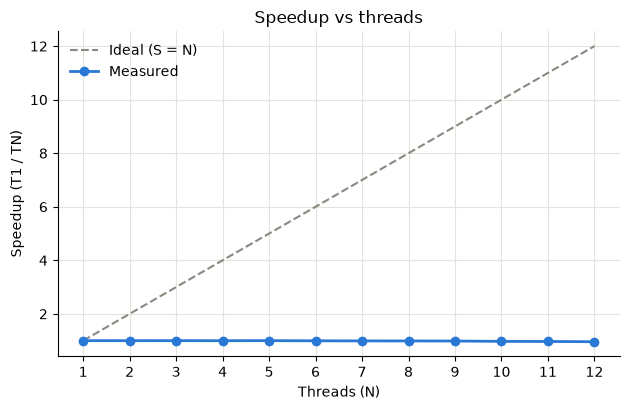

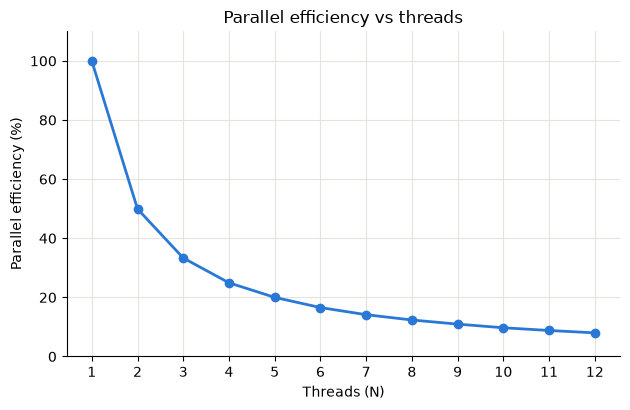

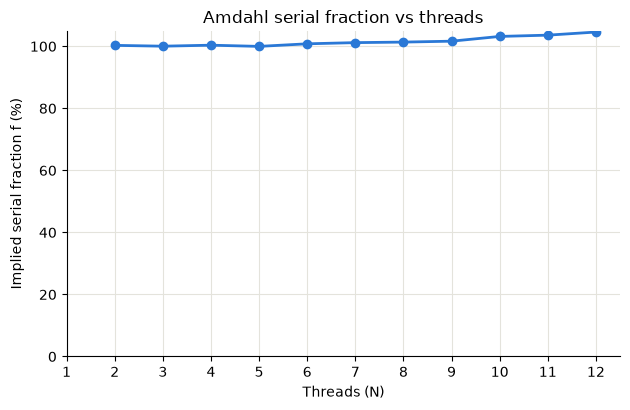

In [13]:


threads = [r["threads"] for r in n_res]
speedup = [r["speedup"] for r in n_res]
efficiency = [r["efficiency"] for r in n_res]

f_threads = [n for n in threads if n > 1]
serial = [((n / s) - 1) / (n - 1) * 100 for n, s in zip(threads, speedup) if n > 1]

BLUE, GREY = "#2a78d6", "#8a8980"

def tidy(ax, ylabel, title):
    ax.set_xlabel("Threads (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(threads)
    ax.grid(True, color="#e4e3dc")
    ax.spines[["top", "right"]].set_visible(False)

# 1. Speedup vs ideal
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, threads, "--", color=GREY, label="Ideal (S = N)")
ax.plot(threads, speedup, "o-", color=BLUE, linewidth=2, label="Measured")
tidy(ax, "Speedup (T1 / TN)", "Speedup vs threads")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

# 2. Efficiency
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(threads, efficiency, "o-", color=BLUE, linewidth=2)
ax.set_ylim(0, 110)
tidy(ax, "Parallel efficiency (%)", "Parallel efficiency vs threads")
fig.tight_layout(); plt.show()

# 3. Serial fraction
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(f_threads, serial, "o-", color=BLUE, linewidth=2)
ax.set_ylim(bottom=0)
tidy(ax, "Implied serial fraction f (%)", "Amdahl serial fraction vs threads")
fig.tight_layout(); plt.show()